# Linguistic strategies beyond P4

**Do selected linguistic differences add predictive value beyond P4?** Keep P4's word count, mean content-word Zipf, log-transformed reply delay, and external-link presence. P6 adds net positive sentiment, OP–reply cosine similarity, and four ConvoKit indicators from the exploratory comparison: direct start, first-person plural, factuality, and direct question.

Each input is the A-minus-B feature difference. Both models use the archived P4 logistic regression specification, with L2 regularization and standardization fitted separately in each training fold. Reproduce P4's saved predictions before comparing it with P6 on the same three OP-discussion-grouped folds. The six added features were selected after the descriptive review on these training pairs, making this a training-only follow-up comparison.

[Exploratory analysis](../strategies/paired_linguistic_strategies.ipynb) · [Training script](train_p6_adjusted_linguistic_strategies.py)

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import display

REPO = next(
    p for p in (Path.cwd(), *Path.cwd().parents)
    if (p / "team-setup").is_dir() and (p / "pyproject.toml").is_file()
)
DATA = REPO / "project/data/processed/linguistic-features"
RUNS = DATA / "paired-models/p6_adjusted_linguistic_strategies"
RUN_ID = None
runs = sorted(RUNS.glob("*/results.json"))
if RUN_ID is None and not runs:
    raise FileNotFoundError("Run train_p6_adjusted_linguistic_strategies.py first.")
report_path = RUNS / RUN_ID / "results.json" if RUN_ID else runs[-1]
run = report_path.parent
report = json.loads(report_path.read_text())
assert report["split"] == "train"
print(f"{report['pairs']:,} training pairs across {report['discussions']:,} OP discussions and {report['folds']} folds.")

3,451 training pairs across 2,507 OP discussions and 3 folds.


## Out-of-fold comparison

ROC-AUC is the primary comparison. Average precision, pairwise accuracy, and log loss show other aspects of performance. Intervals use 1,000 paired bootstrap draws by OP discussion with the predictions fixed.

In [2]:
comparison = pd.read_csv(run / "predictive_comparison.csv").set_index("metric")
display(comparison.round(5))

,p4,p6,p6_minus_p4,ci_low,ci_high
metric,,,,,
ROC-AUC,0.73125,0.74681,0.01556,0.00856,0.02249
Average precision,0.71836,0.73410,0.01574,0.00781,0.02384
Pairwise accuracy,0.66734,0.68009,0.01275,0.00229,0.02353
Log loss,0.60787,0.59657,-0.01129,-0.01640,-0.00612


## Length sensitivity and adjusted associations

The length-matched figures describe pairs within 50 words where the feature differed. The adjusted coefficients come from the joint P6 fit. Each coefficient is the change in log odds per one training standard deviation of the signed feature difference, holding the other features fixed. Intervals refit the model after resampling whole OP discussions, with the training scale fixed. These are exploratory estimates for the selected specification.

In [3]:
names = {
    "net_sentiment": "Net positive sentiment", "op_cosine": "OP–reply similarity",
    "strategy::Direct start": "Direct start", "strategy::1st person pl.": "First-person plural",
    "strategy::Factuality": "Factuality", "strategy::Direct question": "Direct question",
}
summaries = DATA / "paired-linguistic-strategy-summary"
exploratory_paths = [
    path for path in sorted(summaries.glob("*/results.json"))
    if json.loads(path.read_text())["feature_run"] == report["strategy_run"]
]
descriptive = pd.read_csv(exploratory_paths[-1].with_name("paired_strategy_associations.csv"))
selected = descriptive.loc[descriptive["group_type"].eq("overall") & descriptive["feature"].isin(names)].copy()
selected["feature"] = selected["feature"].map(names)
display(selected.set_index(["cohort", "feature"])[[
    "non_ties", "winner_higher_rate", "winner_higher_ci_low", "winner_higher_ci_high",
]].round(4))

coefficients = pd.read_csv(run / "adjusted_coefficients.csv")
added = coefficients.loc[coefficients["feature"].isin(report["added_features"])].copy()
added["strategy"] = added["feature"].str.removeprefix("a_minus_b_").map(names)
display(added.set_index("strategy")[[
    "coefficient", "ci_low", "ci_high", "informative_pairs", "informative_discussions",
]].round(4))

non_ties  winner_higher_rate  winner_higher_ci_low  winner_higher_ci_high
cohort             feature                                                                                          
All training pairs Net positive sentiment      3450              0.5435                0.5262                 0.5606
                   OP–reply similarity         3450              0.4881                0.4708                 0.5070
                   Factuality                  1513              0.5605                0.5335                 0.5882
                   First-person plural         1397              0.5662                0.5382                 0.5947
                   Direct question             1376              0.5509                0.5221                 0.5798
                   Direct start                1654              0.5732                0.5480                 0.5988
Within 50 words    Net positive sentiment      1143              0.5249                0.4955                 0.5561
                   OP–reply similarity         1143              0.4584                0.4295                 0.4842
                   Factuality                   438              0.5023                0.4521                 0.5502
                   First-person plural          415              0.5157                0.4646                 0.5610
                   Direct question              408              0.5221                0.4707                 0.5701
                   Direct start                 524              0.5267                0.4826                 0.5717

,coefficient,ci_low,ci_high,informative_pairs,informative_discussions
strategy,,,,,
Net positive sentiment,0.1231,0.0459,0.1991,3450,2506
OP–reply similarity,-0.3354,-0.4164,-0.2621,3450,2506
Direct start,0.0662,-0.0161,0.1469,1654,1410
First-person plural,0.0073,-0.0722,0.0846,1397,1177
Factuality,0.0225,-0.0601,0.1076,1513,1272
Direct question,0.0456,-0.0343,0.1294,1376,1199


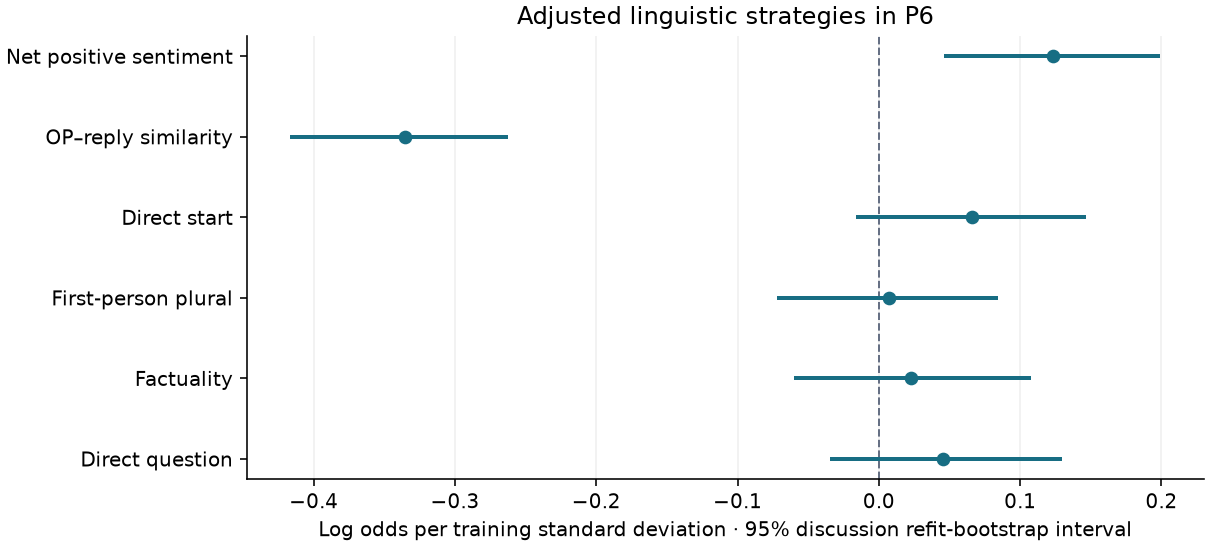

In [4]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8.4, 3.8), layout="constrained")
y = np.arange(len(added))
ax.axvline(0, color="#667084", linestyle="--", lw=1)
ax.hlines(y, added["ci_low"], added["ci_high"], color="#176d83", lw=2)
ax.scatter(added["coefficient"], y, color="#176d83", s=34, zorder=3)
ax.set_yticks(y, added["strategy"])
ax.invert_yaxis()
ax.set(title="Adjusted linguistic strategies in P6",
       xlabel="Log odds per training standard deviation · 95% discussion refit-bootstrap interval")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="x", alpha=0.20)
plt.show()

## Interpretation

The fixed six-feature extension raised out-of-fold ROC-AUC by 0.0156. The adjusted model assigned positive weight to net sentiment and negative weight to OP–reply similarity. All four individual ConvoKit coefficient intervals crossed zero. The predictive comparison estimates the contribution of the six features together, so it leaves the contribution of each individual feature unresolved. These training results follow feature selection on the same data and are exploratory.